# Using Diffusion on prediction of video and motion

## Import the lib and initialize the parameters

In [1]:
import argparse
import os.path

import torch
from torch import nn, optim
from torch import nn
from torch.utils.data import DataLoader
from tqdm import tqdm
from dataset.dataset_loader import VideoDataset
import torch.nn.functional as F



In [2]:
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(DEVICE)
# The parser setting
parser = argparse.ArgumentParser()
parser = VideoDataset.add_model_specific_args(parser)
parser.add_argument('--data_path', type=str, default='dataset/2024-10-31_xacti_5fps')
# parser.add_argument('--data_path', type=str, default='dataset/mul_fps_data')

parser.add_argument('--sequence_length', type=int, default=40)
parser.add_argument('--resolution', type=int, default=64)
parser.add_argument('--batch_size', type=int, default=16)
parser.add_argument('--num_workers', type=int, default=8)
parser.add_argument('--LR_RATE', type=int, default=1e-4)
parser.add_argument('--NUM_EPOCHS', type=int, default=100)
parser.add_argument('--iteration_num', type=int, default=1000)
args = parser.parse_args(args=[])
mulgpu = False
rgb = False

cuda:0


## 1. Load the Dataset

In [3]:
# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(args.data_path, args.sequence_length,rgb=rgb, train=True, resolution=args.resolution)

# dataloader for the trainning
dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=True
)

# dataloader for the evaluation
dataset = Dataset(args.data_path, args.sequence_length, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

metadata exists in: dataset/2024-10-31_xacti_5fps/train/metadata_40.pkl
metadata exists in: dataset/2024-10-31_xacti_5fps/test/metadata_40.pkl


## 2. Load the networks

In [4]:
from utils import fw_diffusion_vid, fw_diffusion_mot, MixedSequenceMaskGenerator
input_mot_channel = args.sequence_length * 2
mask_generator = MixedSequenceMaskGenerator(t2=args.sequence_length)

# The parameters for forward diffusion process
beta = torch.linspace(1e-4, 0.02, args.iteration_num) 
alpha = 1.0-beta
alpha_cum = torch.tensor([alpha[0]] + [torch.prod(alpha[:i+1]) for i in range(1, len(beta))])

## 3. Train the model

### 3.1 Continue from the checkpoint

In [5]:
from TimeSformer.VDT_cat_vm import VDT_cat
from DDIM.ddim import remove_module_prefix
nhead = 6
depth = 12
patch_size= 2
hidden_size = 768
epoch = 200
in_channels = 6
input_size = 8

eps_est_model = VDT_cat(
    input_size=input_size,
    patch_size=patch_size,
    in_channels=in_channels,
    hidden_size=hidden_size,
    depth=depth,
    num_frames=args.sequence_length,
    num_heads=nhead,
    mlp_ratio=4.0,
    learn_sigma=False
    ).to(DEVICE)


from diffusers.models import AutoencoderKL
vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse").to(DEVICE)
vae.encoder.conv_in = nn.Conv2d(9, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, 9, kernel_size=3, stride=1, padding=1)


if mulgpu:
    if rgb:
        input_dim = 3
        modelData = 'checkpoints_vae_seg/vae_20241116_rgb40.pth.tar'
        checkpoint = torch.load(modelData)
        state_dict = checkpoint['model_state_dict']
        state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
    else:
        input_dim = 9
        modelData = 'checkpoints_vae_seg/vae_20241031_40.pth.tar'
        checkpoint = torch.load(modelData)
        state_dict = checkpoint['model_state_dict']
        state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
else:
    if rgb:
        input_dim = 3
        modelData = 'checkpoints_vae_seg/vae_20241116_rgb40.pth.tar'
        checkpoint = torch.load(modelData, map_location=torch.device('cpu'))
        state_dict = checkpoint['model_state_dict']
        state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
    else:
        input_dim = 9
        modelData = 'checkpoints_vae_seg/vae_20241031_40.pth.tar'
        checkpoint = torch.load(modelData, map_location=torch.device('cpu'))
        state_dict = checkpoint['model_state_dict']
        state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}

vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse")
vae.encoder.conv_in = nn.Conv2d(input_dim, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, input_dim, kernel_size=3, stride=1, padding=1)
vae.load_state_dict(state_dict)
vae.to(DEVICE)

# freeze vae
for param in vae.parameters():
    param.requires_grad = False



In [8]:
sum([p.numel() for p in eps_est_model.parameters()])

165333906

## 4. Tests

### Multi-result generation (Input with multiple batches)

In [6]:
valid_dataset = Dataset(args.data_path, args.sequence_length, rgb=rgb,train=True, resolution=args.resolution)

metadata exists in: dataset/2024-10-31_xacti_5fps/train/metadata_40.pkl


load model: success
11 dataset/2024-10-31_xacti_5fps/train/1 copy/3.mp4
li:0.157 ang:0.000
li:0.148 ang:0.000
li:0.189 ang:0.000
li:0.231 ang:0.000
li:0.189 ang:0.000
li:0.164 ang:0.000
li:0.160 ang:0.000
li:0.189 ang:-0.200
li:0.192 ang:-0.400
li:0.104 ang:-0.400
li:0.358 ang:-0.500
li:0.199 ang:-0.400
li:0.174 ang:-0.400
li:0.110 ang:-0.100
li:0.281 ang:0.000
li:0.206 ang:0.000
li:0.266 ang:0.000
li:0.234 ang:0.000
li:0.228 ang:0.000
li:0.228 ang:0.000
li:0.248 ang:0.000
li:0.270 ang:0.000
li:0.139 ang:0.000
li:0.176 ang:0.000
li:0.238 ang:0.000
li:0.152 ang:0.000
li:0.148 ang:0.400
li:0.202 ang:0.400
li:0.290 ang:0.400
li:0.157 ang:0.000
torch.Size([40, 64, 64, 9])
torch.Size([40, 64, 64, 9])
torch.Size([40, 64, 64, 9])
li:0.161 ang:-0.069
li:0.159 ang:-0.115
li:0.136 ang:-0.324
li:0.137 ang:-0.327
li:0.184 ang:-0.289
li:0.184 ang:-0.046
li:0.192 ang:-0.002
li:0.123 ang:-0.002
li:0.159 ang:0.005
li:0.216 ang:0.004
li:0.158 ang:0.000
li:0.189 ang:-0.002
li:0.176 ang:0.003
li:0.199 an

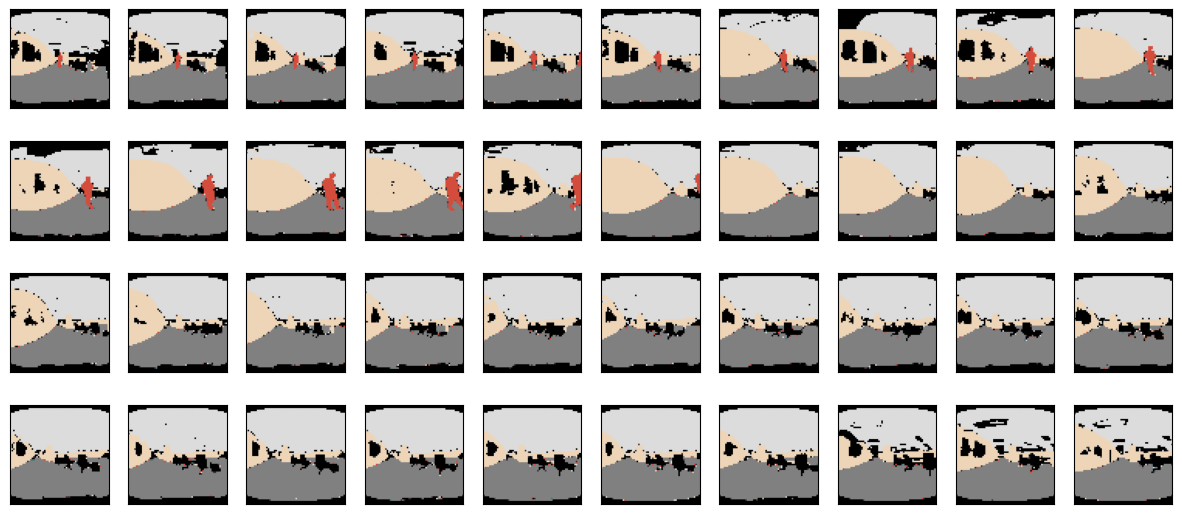

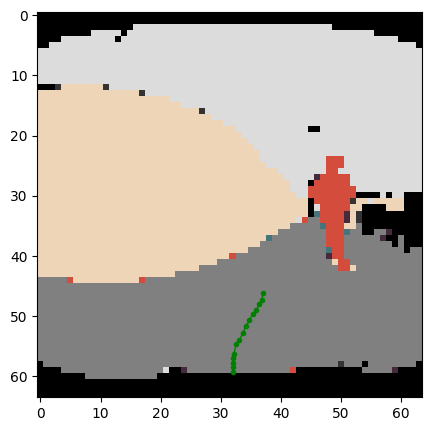

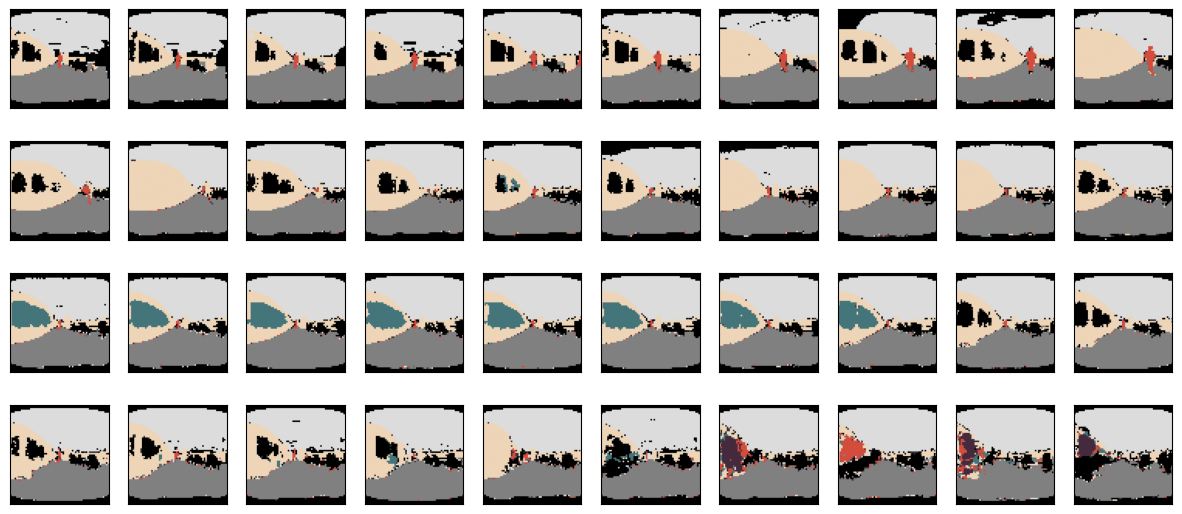

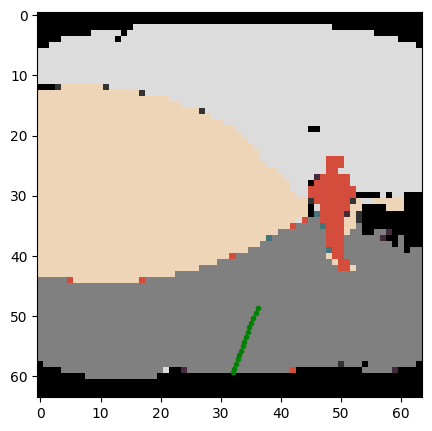

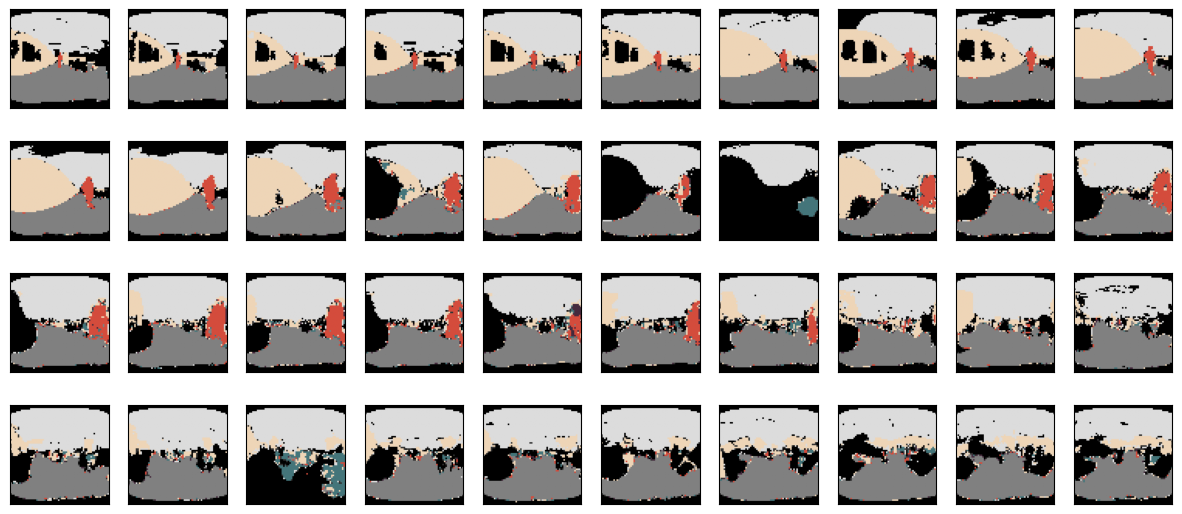

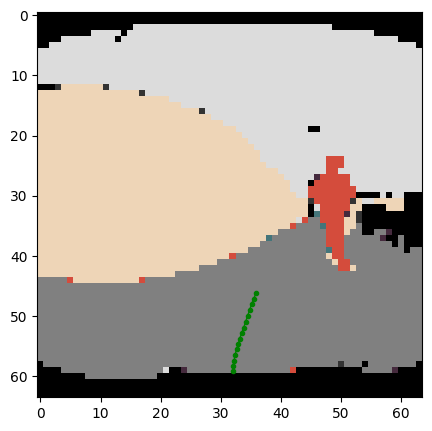

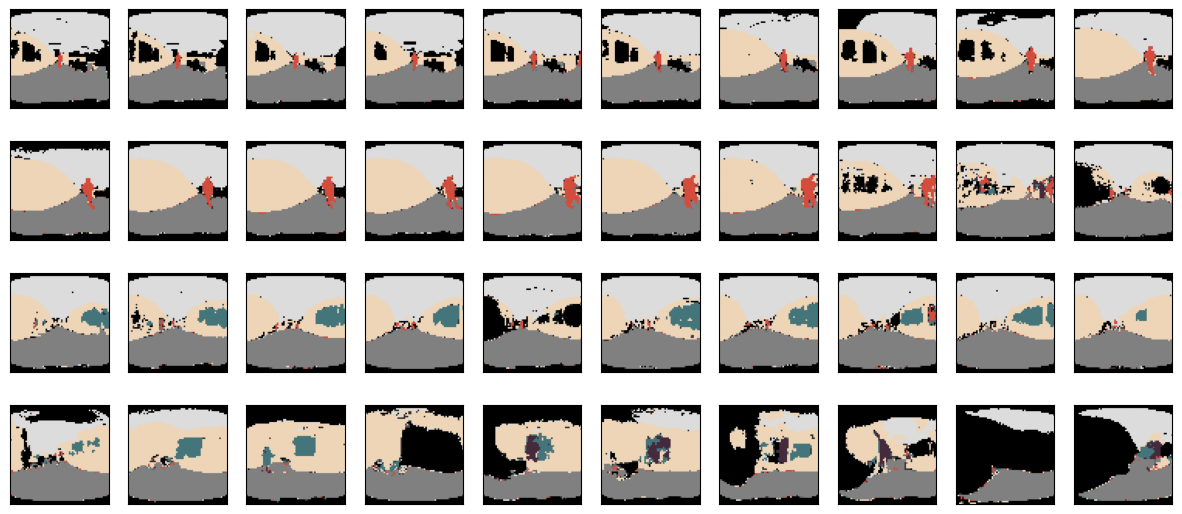

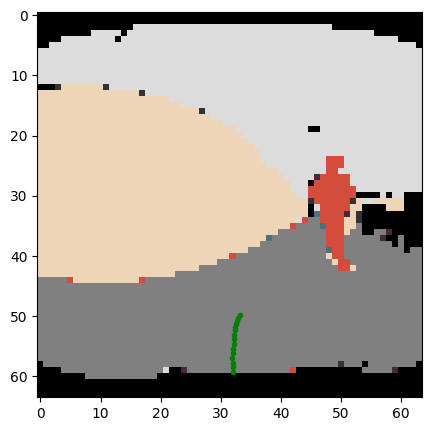

In [23]:
import numpy as np
np.set_printoptions(threshold=np.inf, linewidth=np.inf)

from DDIM.ddim import ddim_generator
from utils import mask_vid_mot, visual_vid_mmot, gray2color
import time

# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241031_halfmask_rgb_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241031_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'
# modelData = 'checkpoints_mmVDT_cat_vae_seg/VDT_20241220_test_halfmask_seg_xacti_5fps_seq40_mgpu_d'+str(depth)+'_h'+str(hidden_size)+'_nh'+str(nhead)+'_np'+str(patch_size)+'_it'+str(args.iteration_num)+'_'+str(epoch)+'.pth.tar'

ddim_generator = ddim_generator(nit=args.iteration_num,patch_size=patch_size,nhead=nhead,input_size=input_size, in_channels=in_channels, 
                                depth=depth, hidden_size=hidden_size, model_path=modelData, sequence_length=args.sequence_length,_cuda=0, cat=True)

idx=475
# Pick a sample in the dataset
# memo: 20241031_data 475, 8000, 12318, 12949, 13180, 13344, 13350, 14000, 16000, 18500, 19206
# memo: 20241031_test_data 800, 3000, 3335
r = 3
vis_id = 0 # the index for visualization, default = 0
pred_num = 3 # The number of multiple predictions
frame_t = 10 

test = True
batch, vid_idx, path = valid_dataset[idx]
print(vid_idx, path)
batch, mot = dict.values(batch)

mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
start_time = time.time()

vid = batch.permute(0,3,1,2).to(DEVICE)
enc_vid = vae.encode(vid).latent_dist.sample()
enc_vid = enc_vid.reshape(1, args.sequence_length,4,8,8).permute(0,1,3,4,2)

a = enc_vid.to(DEVICE)
b = mot.to(DEVICE)
rec_vid_list = []
rec_mot_list = []
dec_vid_list = []

################ Original image #############################
batch = batch.permute(0,3,1,2)
dec_vid_list.append(batch.permute(0,2,3,1))
rec_mot_list.append(b[vis_id].reshape(1,args.sequence_length,2))
if rgb:
    batch_rgb = batch
else:
    batch_rgb = gray2color(batch)
    batch_rgb = torch.clamp(batch_rgb, 0,1)

    
visual_vid_mmot(batch_rgb.permute(0,2,3,1), b[vis_id].reshape(1,args.sequence_length,2), rgb=True, frame_t=frame_t,grid=False)

if test:
    diff_a = torch.randn([pred_num,args.sequence_length,input_size,input_size,in_channels-2]).to(DEVICE)
    diff_b = torch.randn([pred_num,args.sequence_length,2]).to(DEVICE)

# Choose a mask type from 0 to 2
# 0: prediction 1: backward 2: interpolation, t means the current frame
mask_vid, mask_motion, _ = mask_generator(diff_a,diff_b, idx=0, t=frame_t)

##################### Mask the video or not ##############################
# mask_vid = torch.zeros_like(diff_a)
###########################################################################

# print(mask_vid[0,4])
a = a.repeat(pred_num,1,1,1,1)
b = b.repeat(pred_num,1,1)
############################################################
# mask_motion = torch.zeros_like(diff_b)
# b = torch.tensor([[0.3,-0.]])
# b = b.repeat(1,args.sequence_length,1).repeat(pred_num,1,1).to(DEVICE)
############################################################
diff_a, diff_b = mask_vid_mot(mask_vid,mask_motion, a, b, diff_a, diff_b)


with torch.no_grad():
    rec_vid, rec_mot = ddim_generator(diff_a,diff_b,mask_vid,mask_motion,ncal=16) #ncal: the ddim sample steps
    
rec_vid = rec_vid.reshape(pred_num,args.sequence_length,input_size,input_size,in_channels-2).permute(0,1,4,2,3)
est_time = time.time() - start_time

################ Decode image #############################
for i in range(pred_num):  
    rec_mot_list.append(rec_mot[i]) 
    # print(rec_vid[i].permute(0,2,3,1)[0,5,0])
    dec_vid = vae.decode(rec_vid[i]).sample
    dec_vid_list.append(dec_vid.permute(0,2,3,1))
    print(dec_vid.permute(0,2,3,1).shape)
    if rgb:
        dec_rgb = torch.clamp(dec_vid, 0,1).permute(0,2,3,1)
    else:
        dec_rgb = gray2color(dec_vid)
        dec_rgb = torch.clamp(dec_rgb, 0,1).permute(0,2,3,1)
    rec_vid_list.append(dec_rgb)

################ Select image (Naive selection) #############################
for t in range(pred_num):
    end_x,end_y = visual_vid_mmot(rec_vid_list[t], [rec_mot_list[t+1]], rgb=True, is_road=True, grid=False, frame_t=frame_t)
    end_x = int(end_x.numpy())
    end_y = int(end_y.numpy())
    # print(end_x, end_y)
    xx, yy = torch.meshgrid(torch.arange(args.resolution), torch.arange(args.resolution), indexing="ij")
    detect_mask = ((xx-end_y)**2 +(yy-end_x)**2) <= r **2
    detected_area = rec_vid_list[t][7][detect_mask]
    # Check the end point is on the floor
    result = torch.all(detected_area == 128/255)
    print(result)

print("estimate time:", est_time)



### Evaluation with Manhattan distance

#### Extract each channel of generated results and calculate Manhattan distance

Frame 1 Manhattan Distances: {'undetected_obs': tensor(0.0995), 'ceiling': tensor(0.0825), 'wall': tensor(0.1182), 'detected_furniture': tensor(0.0395), 'door': tensor(0.0466), 'Human': tensor(0.0761), 'Floor': tensor(0.0738)}
Frame 2 Manhattan Distances: {'undetected_obs': tensor(0.1694), 'ceiling': tensor(0.0989), 'wall': tensor(0.1504), 'detected_furniture': tensor(0.0167), 'door': tensor(0.0461), 'Human': tensor(0.0789), 'Floor': tensor(0.1011)}
Frame 3 Manhattan Distances: {'undetected_obs': tensor(0.1506), 'ceiling': tensor(0.1538), 'wall': tensor(0.1876), 'detected_furniture': tensor(0.0587), 'door': tensor(0.0885), 'Human': tensor(0.1223), 'Floor': tensor(0.0792)}


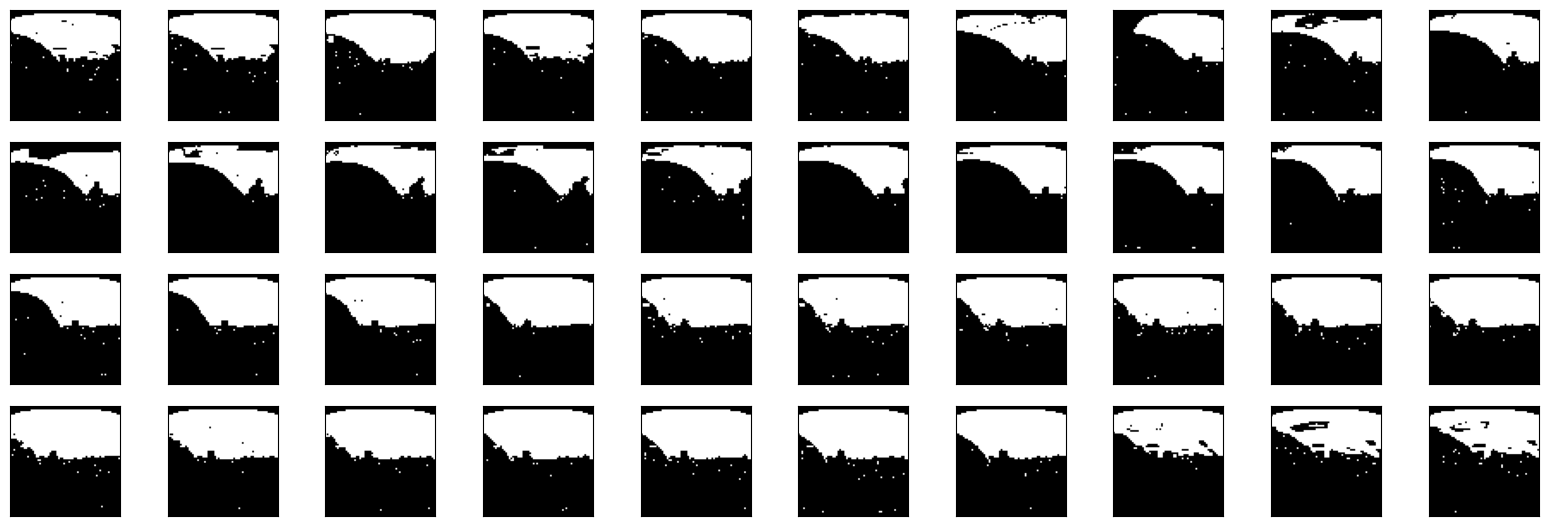

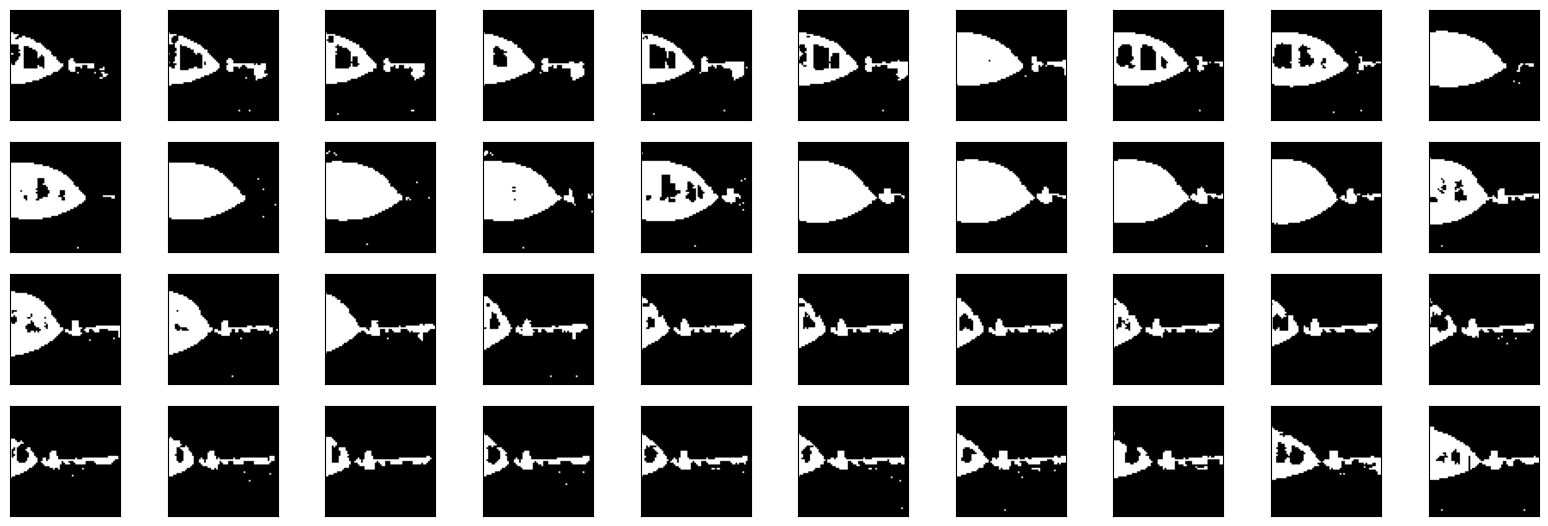

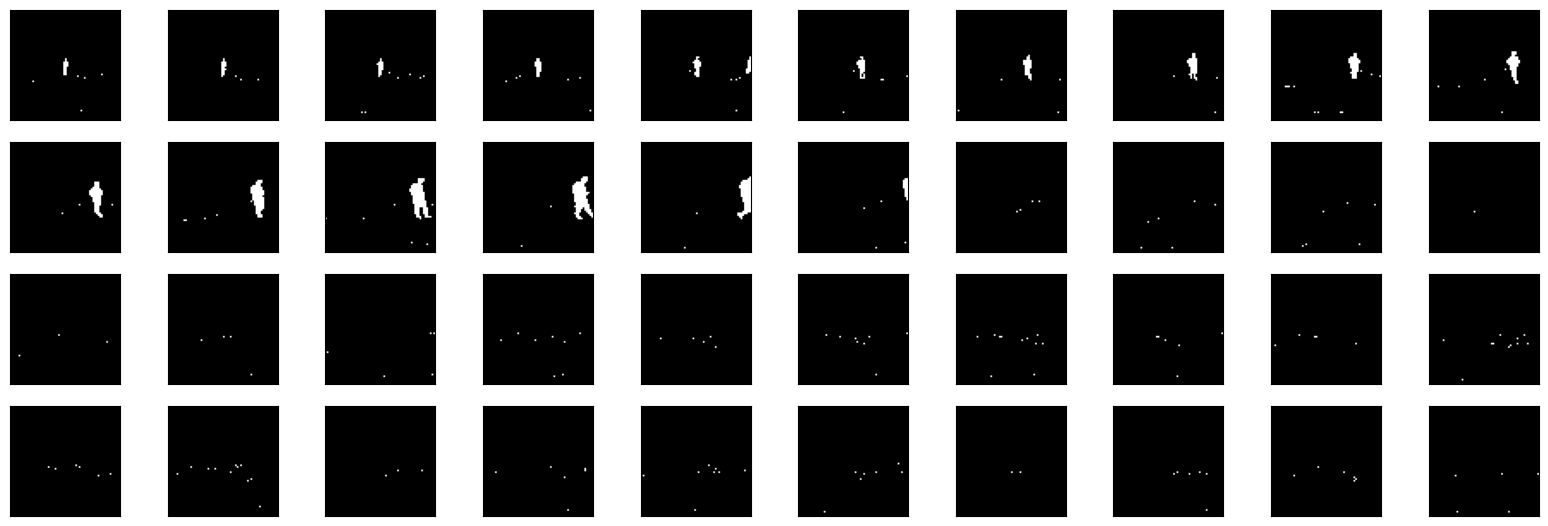

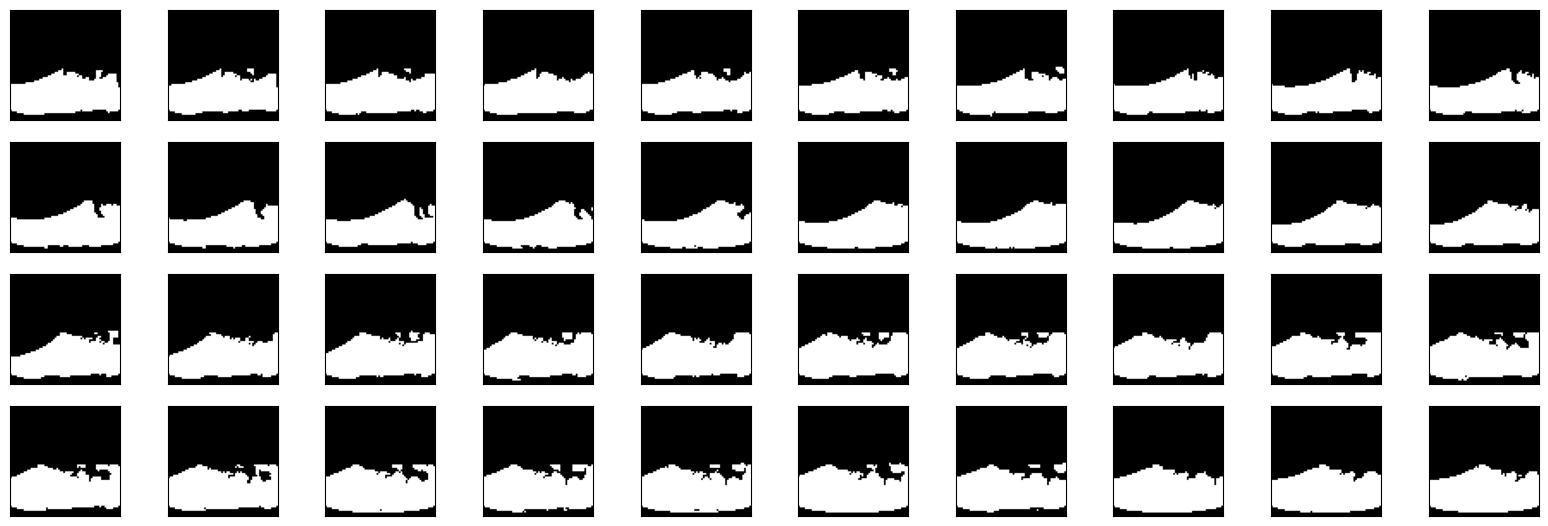

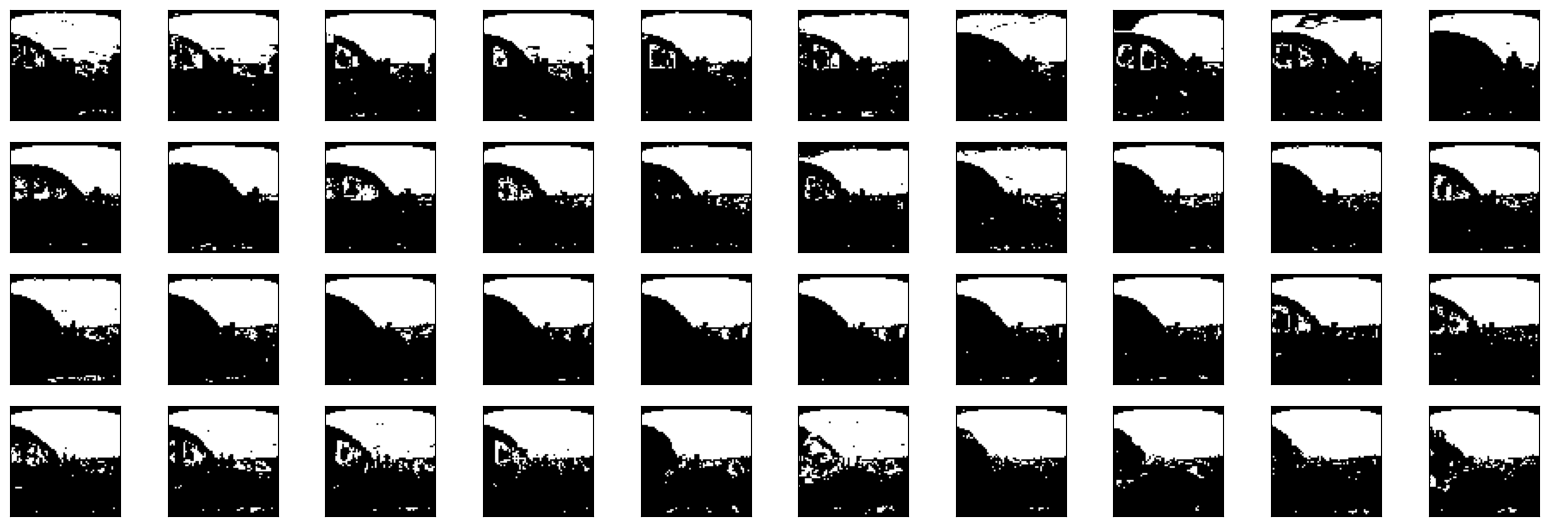

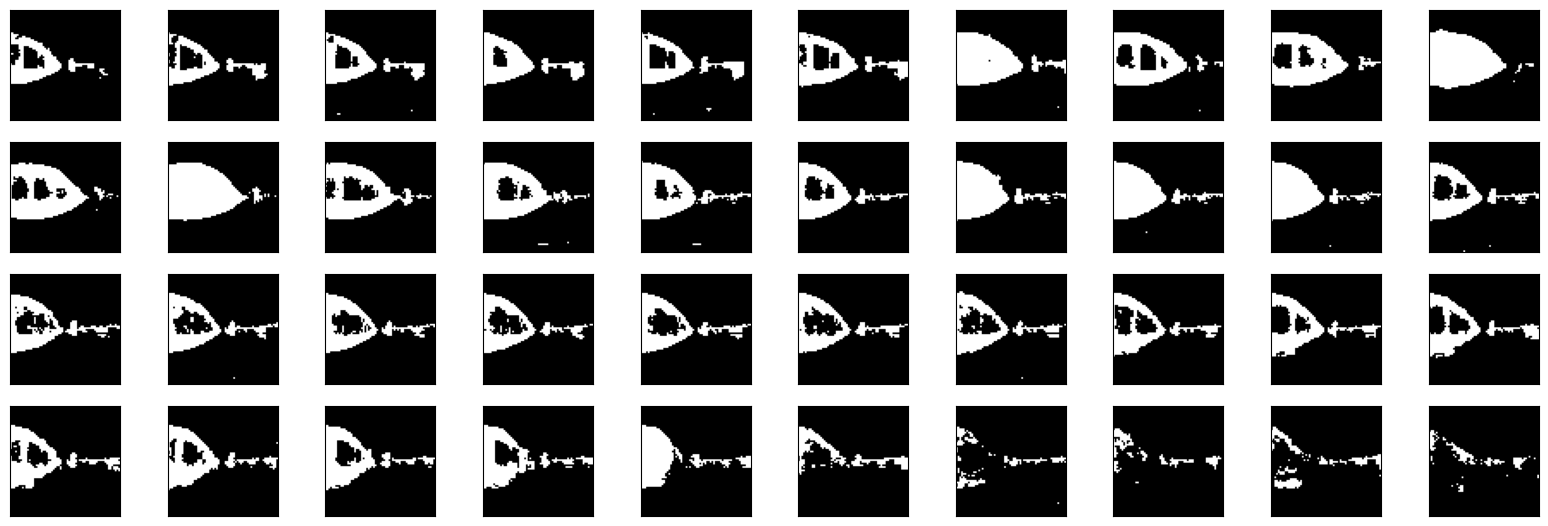

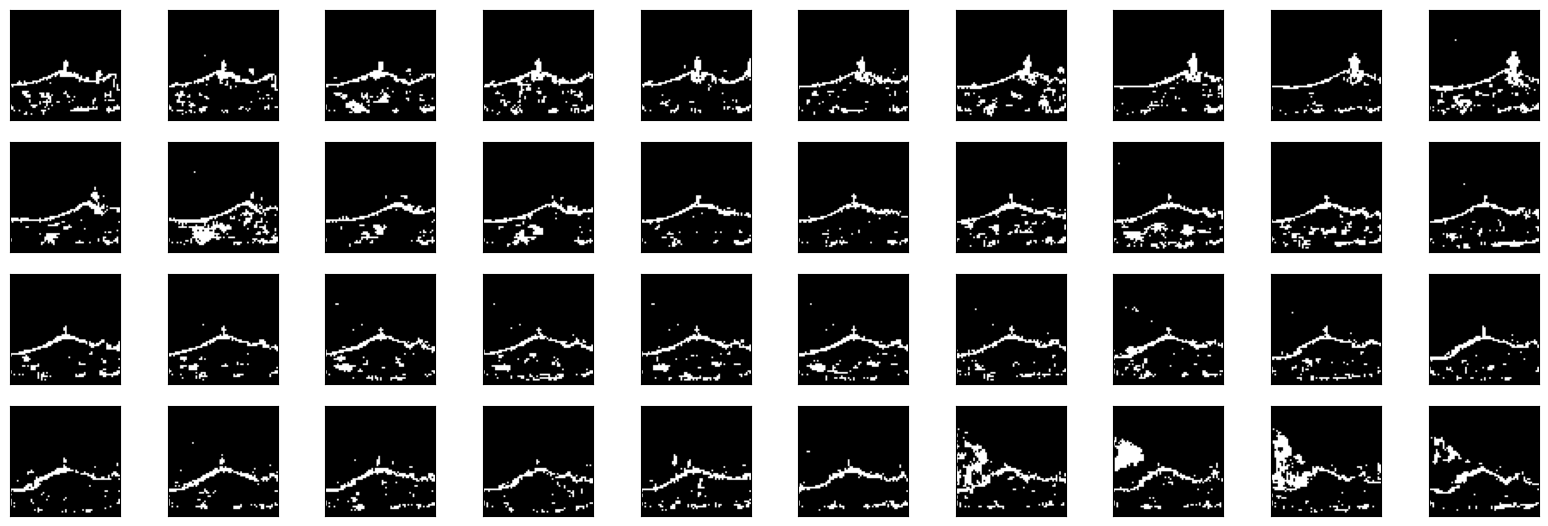

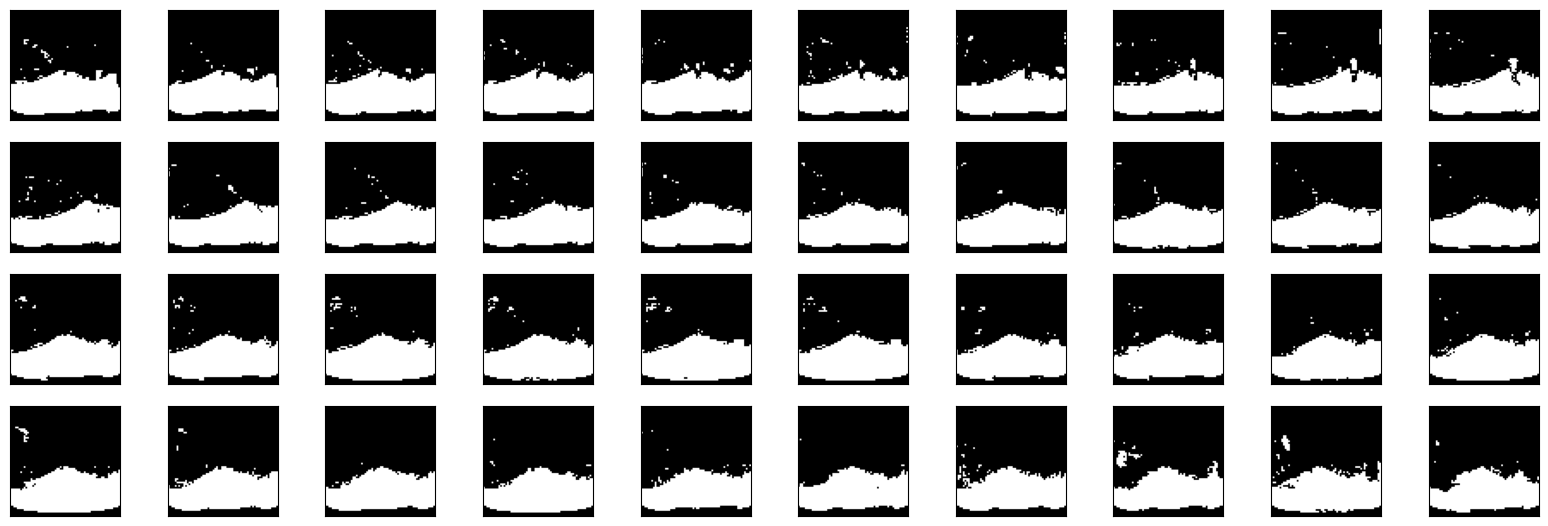

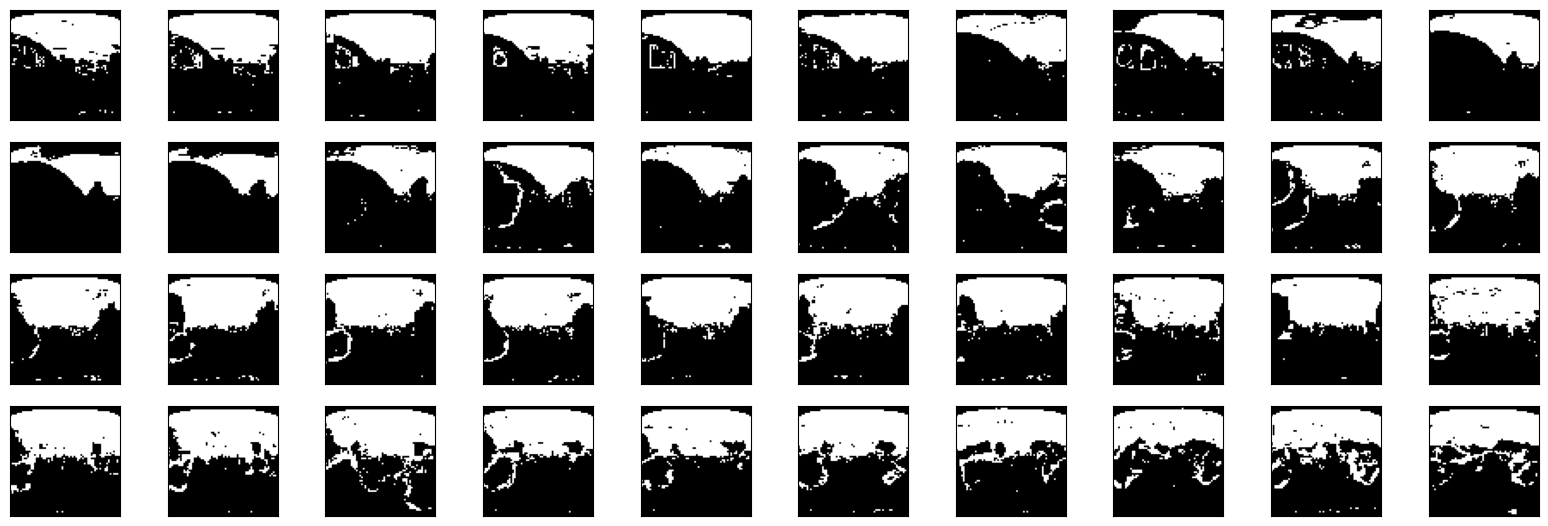

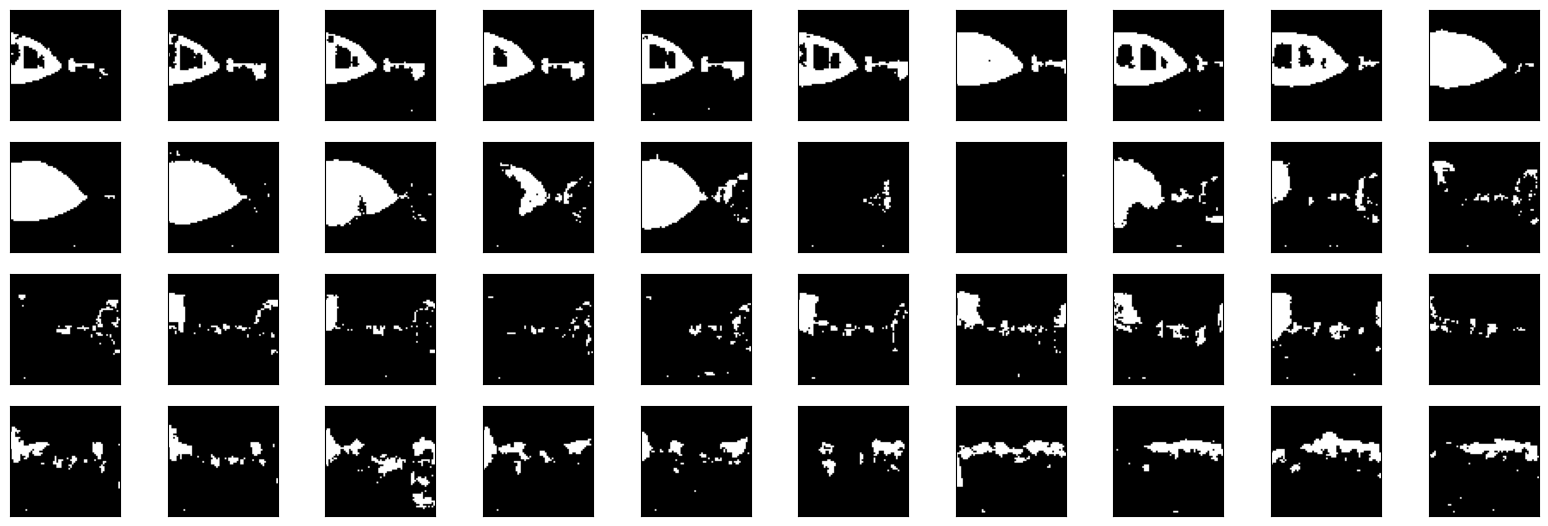

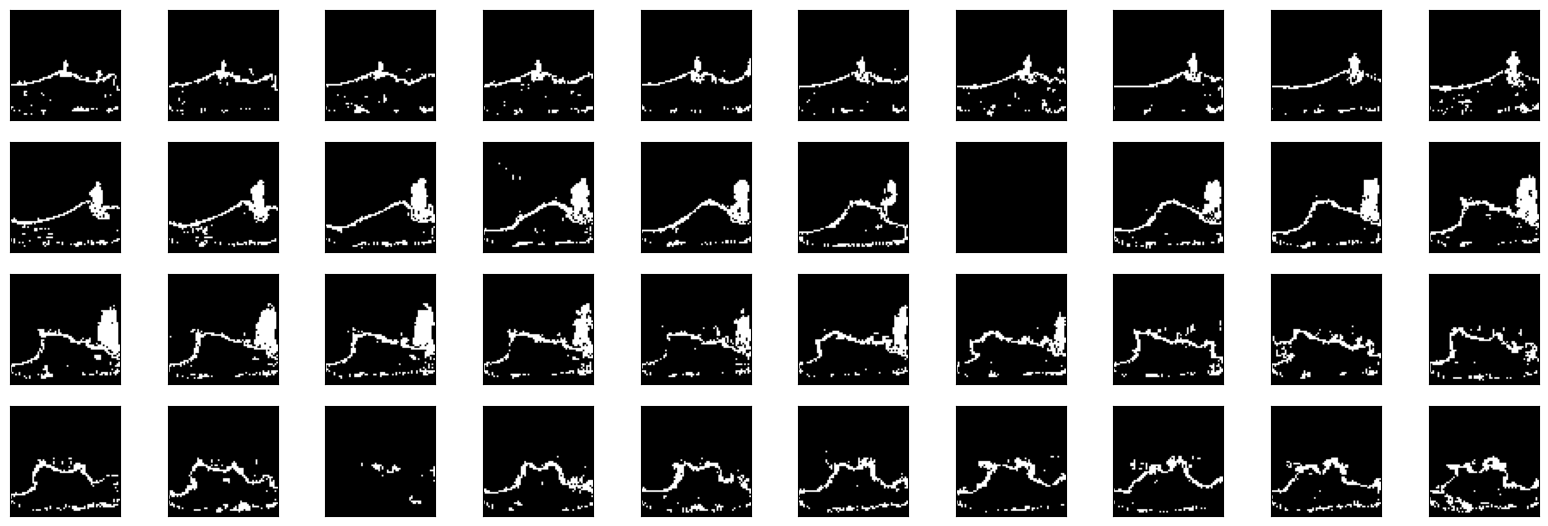

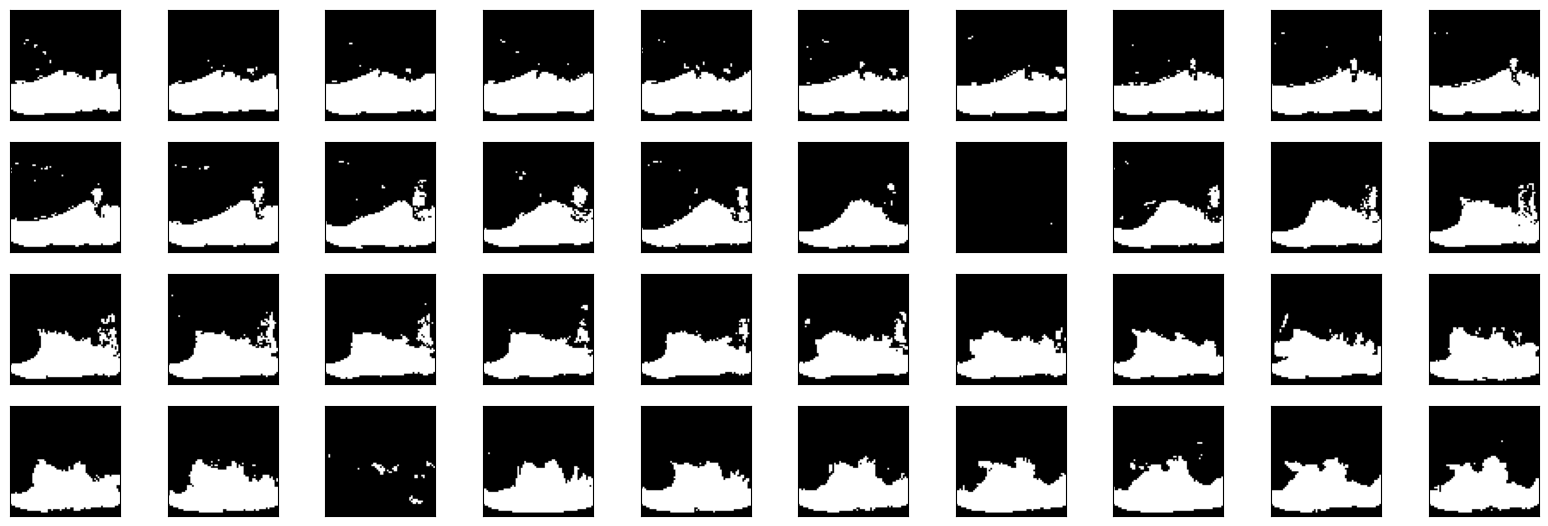

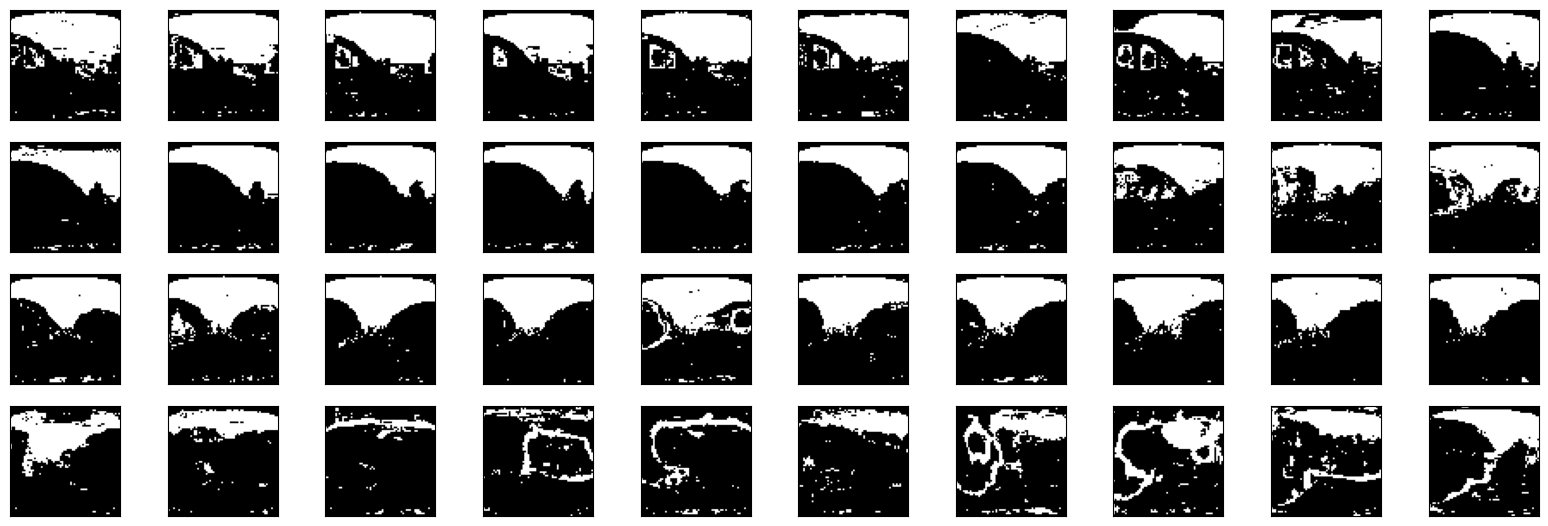

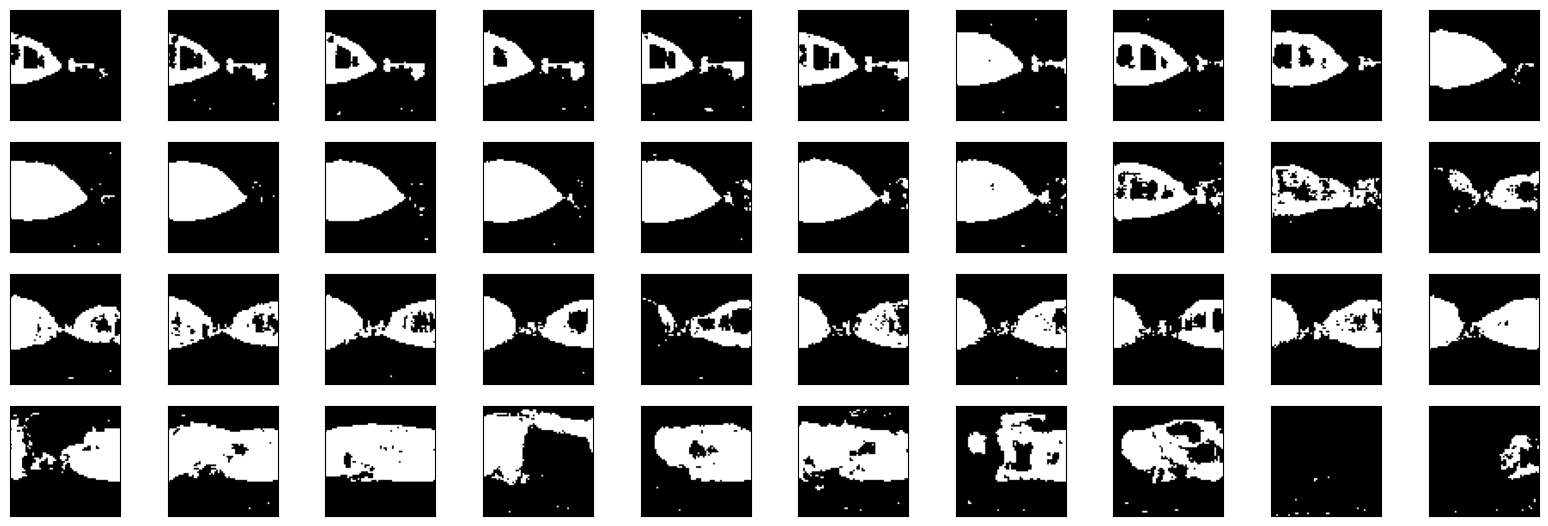

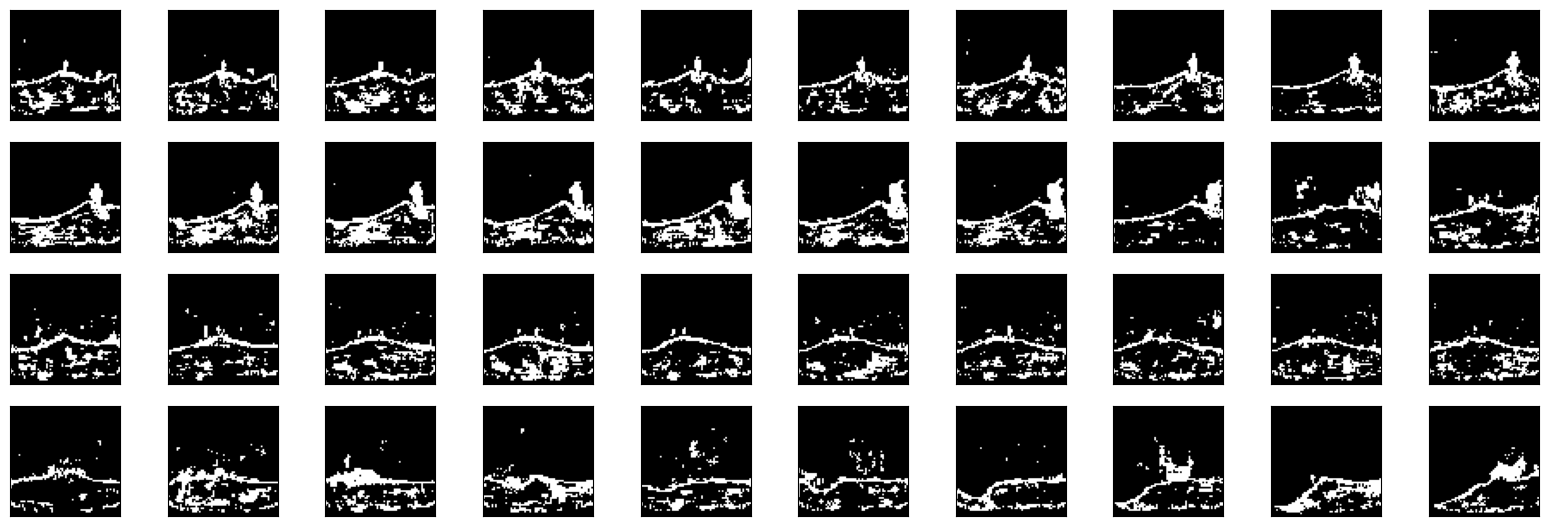

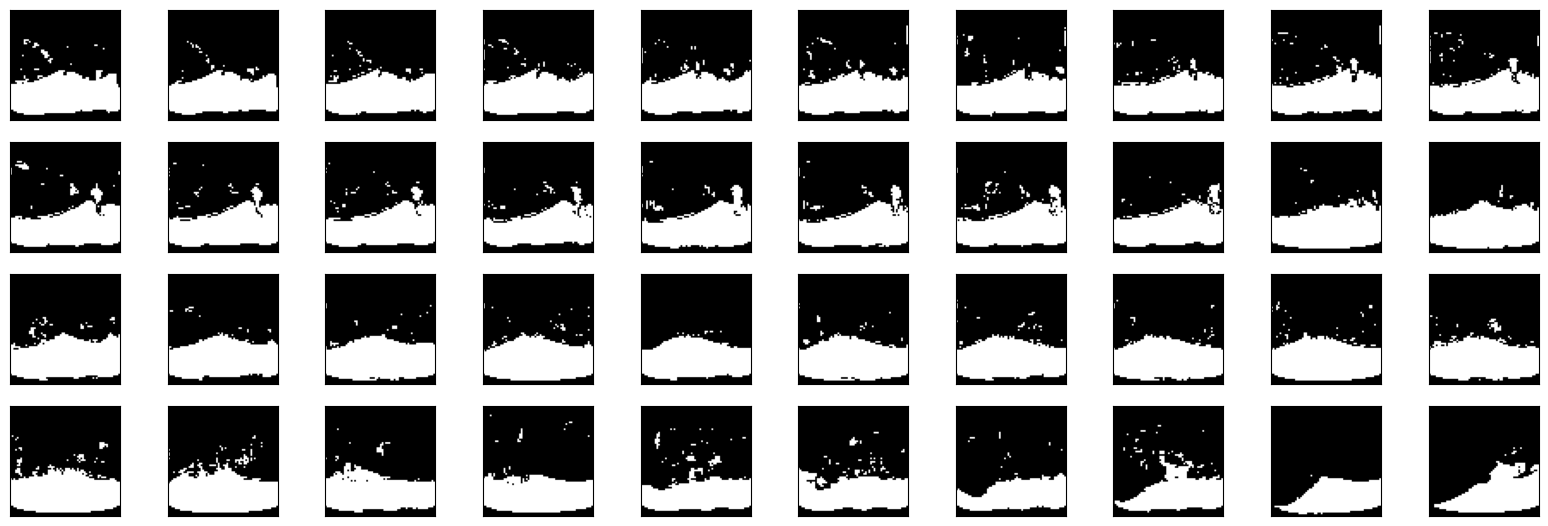

In [24]:
from utils import visual_vid_mmot_each_channel

saved_channels = {}
distances = {}
for t in range(pred_num+1):
    dec_vid = dec_vid_list[t].reshape(1,args.sequence_length,args.resolution,args.resolution,input_dim)
    min_val = dec_vid.min()
    max_val = dec_vid.max()

    # end_x,end_y = visual_vid_mmot(dec_vid, [rec_mot_list[t]], 
    #                             mot_viz=False,rgb=False, is_road=True, grid=False, frame_t=frame_t)
    
    # normalize the video value to [0, 1]
    video_normalized = (dec_vid - min_val) / (max_val - min_val)
    binary_video = (video_normalized > 0.6).float() # 转换为浮点数
    if t == 0:
        # 保存 t=0 时的各个 channel 数据
        saved_channels['undetected_obs'] = visual_vid_mmot_each_channel(binary_video, [rec_mot_list[t]], 
                                                                        channel=0, grid=False, frame_t=frame_t, mot_viz=False, visual_on=False)
        saved_channels['ceiling'] = visual_vid_mmot_each_channel(binary_video, [rec_mot_list[t]], 
                                                                        channel=1, grid=False, frame_t=frame_t, mot_viz=False, visual_on=True)
        saved_channels['wall'] = visual_vid_mmot_each_channel(binary_video, [rec_mot_list[t]], 
                                                                        channel=3, grid=False, frame_t=frame_t, mot_viz=False, visual_on=True)
        saved_channels['detected_furniture'] = visual_vid_mmot_each_channel(binary_video, [rec_mot_list[t]], 
                                                                        channel=4, grid=False, frame_t=frame_t, mot_viz=False, visual_on=False)
        saved_channels['door'] = visual_vid_mmot_each_channel(binary_video, [rec_mot_list[t]], 
                                                                        channel=5, grid=False, frame_t=frame_t, mot_viz=False, visual_on=False)
        saved_channels['Human'] = visual_vid_mmot_each_channel(binary_video, [rec_mot_list[t]], 
                                                                        channel=6, grid=False, frame_t=frame_t, mot_viz=False, visual_on=True)
        saved_channels['Floor'] = visual_vid_mmot_each_channel(binary_video, [rec_mot_list[t]], 
                                                                        channel=7, grid=False, frame_t=frame_t, mot_viz=False, visual_on=True)
    else:
        # 计算 t>0 时的各个 channel 与保存的 channel 之间的曼哈顿距离
        undetected_obs = visual_vid_mmot_each_channel(binary_video, [rec_mot_list[t]], 
                                                                        channel=0, grid=False, frame_t=frame_t, mot_viz=False, visual_on=False)
        ceiling = visual_vid_mmot_each_channel(binary_video, [rec_mot_list[t]], 
                                                                        channel=1, grid=False, frame_t=frame_t, mot_viz=False, visual_on=True)
        wall = visual_vid_mmot_each_channel(binary_video, [rec_mot_list[t]], 
                                                                        channel=3, grid=False, frame_t=frame_t, mot_viz=False, visual_on=True)
        detected_furniture = visual_vid_mmot_each_channel(binary_video, [rec_mot_list[t]], 
                                                                        channel=4, grid=False, frame_t=frame_t, mot_viz=False, visual_on=False)
        door = visual_vid_mmot_each_channel(binary_video, [rec_mot_list[t]], 
                                                                        channel=5, grid=False, frame_t=frame_t, mot_viz=False, visual_on=False)
        Human = visual_vid_mmot_each_channel(binary_video, [rec_mot_list[t]], 
                                                                        channel=6, grid=False, frame_t=frame_t, mot_viz=False, visual_on=True)
        Floor = visual_vid_mmot_each_channel(binary_video, [rec_mot_list[t]], 
                                                                        channel=7, grid=False, frame_t=frame_t, mot_viz=False, visual_on=True)
        # 计算曼哈顿距离
        manhattan_distances = {
            'undetected_obs': torch.mean(torch.abs(undetected_obs - saved_channels['undetected_obs'])),
            'ceiling': torch.mean(torch.abs(ceiling - saved_channels['ceiling'])),
            'wall': torch.mean(torch.abs(wall - saved_channels['wall'])),
            'detected_furniture': torch.mean(torch.abs(detected_furniture - saved_channels['detected_furniture'])),
            'door': torch.mean(torch.abs(door - saved_channels['door'])),
            'Human': torch.mean(torch.abs(Human - saved_channels['Human'])),
            'Floor': torch.mean(torch.abs(Floor - saved_channels['Floor']))
        }
        # 打印或保存曼哈顿距离
        print(f"Frame {t} Manhattan Distances: {manhattan_distances}")
        # 将曼哈顿距离保存到字典中
        distances[f'Sample {t}'] = manhattan_distances

# 将字典写入文件
torch.save(distances, 'eval/manhattan_distances.pt')


#### Draw the histogram

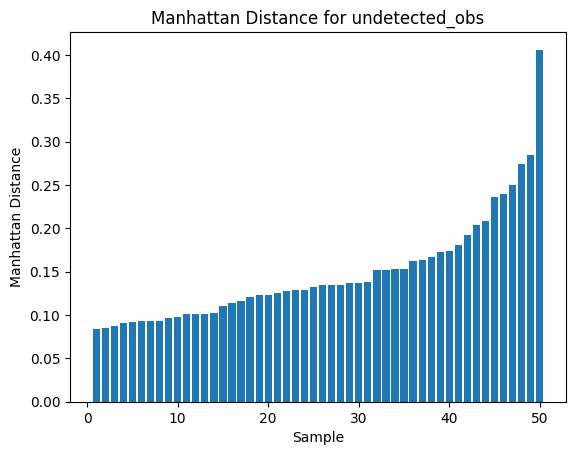

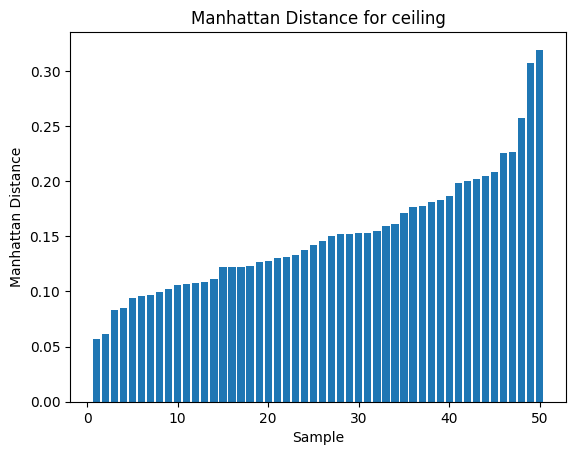

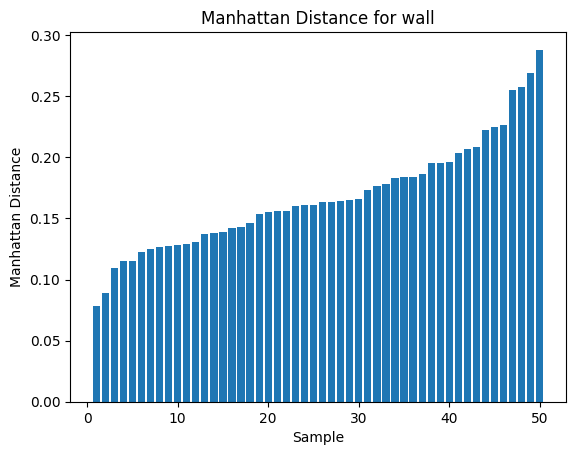

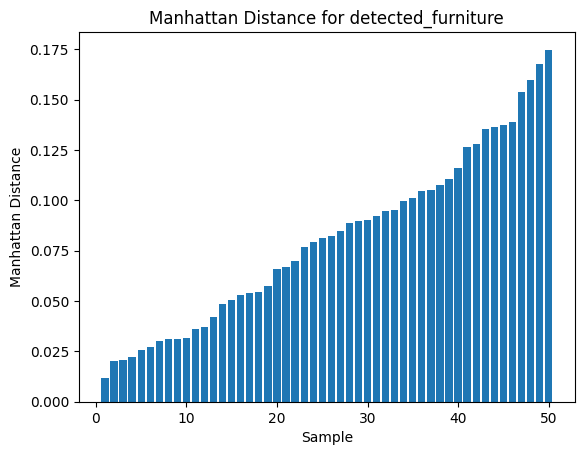

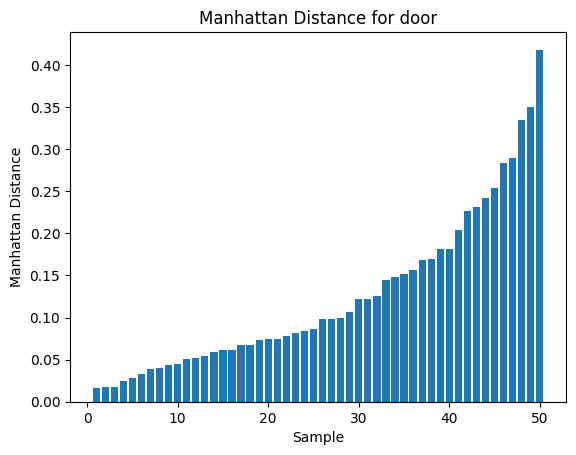

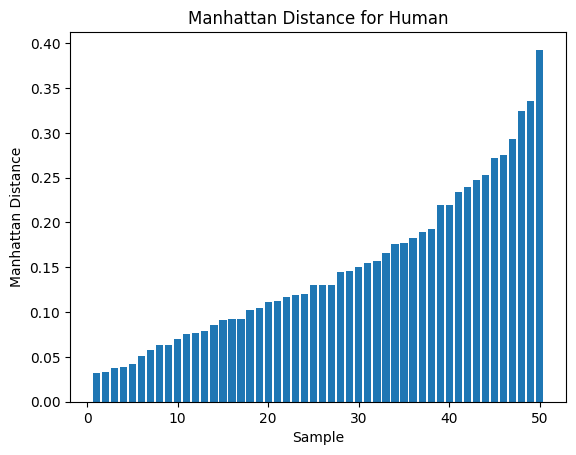

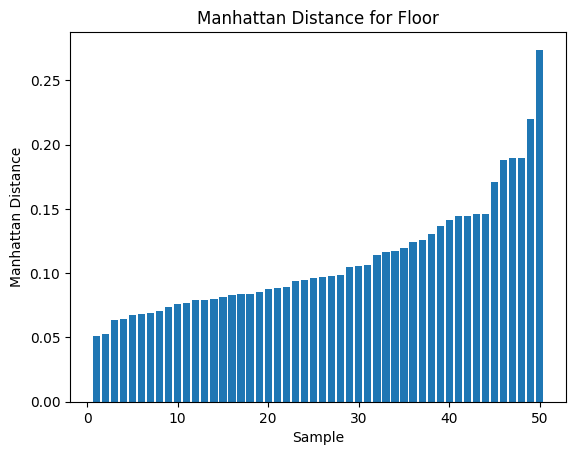

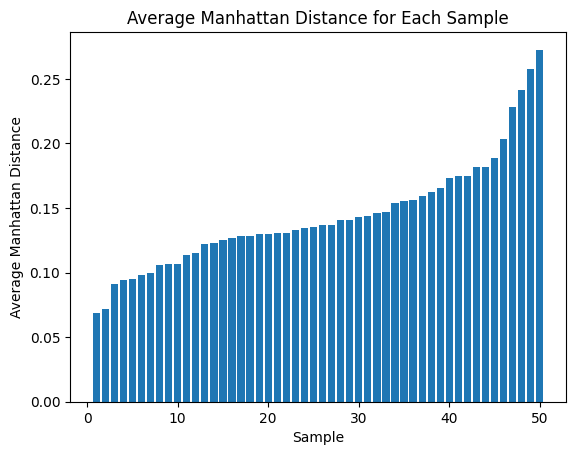

In [19]:
import torch
import matplotlib.pyplot as plt

# 读取 .pt 文件
distances = torch.load('eval/manhattan_distances.pt')

# 提取每个 channel 的曼哈顿距离
channels = ['undetected_obs', 'ceiling', 'wall', 'detected_furniture', 'door', 'Human', 'Floor']
average_channels = [ 'undetected_obs', 'ceiling', 'wall', 'Floor']

channel_distances = {channel: [] for channel in channels}

for sample, distance in distances.items():
    for channel in channels:
        channel_distances[channel].append(distance[channel].item())

# 绘制直方图
for channel in channels:
    sorted_distances = sorted(channel_distances[channel])

    plt.figure()
    plt.bar(range(1, len(sorted_distances) + 1), sorted_distances)
    plt.xlabel('Sample')
    plt.ylabel('Manhattan Distance')
    plt.title(f'Manhattan Distance for {channel}')
    # plt.xticks(range(1, len(sorted_distances) + 2, 10))  # 设置横坐标为正整数
    plt.show()

# 计算每个样本在所有 channel 上的平均曼哈顿距离
average_distances = []
for i in range(len(distances)):
    sample_distances = [channel_distances[channel][i] for channel in average_channels]
    average_distance = torch.mean(torch.tensor(sample_distances)).item()
    average_distances.append(average_distance)


sorted_distances = sorted(average_distances)

# 绘制平均值的直方图
plt.figure()
plt.bar(range(1, len(sorted_distances) + 1), sorted_distances)
plt.xlabel('Sample')
plt.ylabel('Average Manhattan Distance')
plt.title('Average Manhattan Distance for Each Sample')
plt.show()

### Entropy Calculation

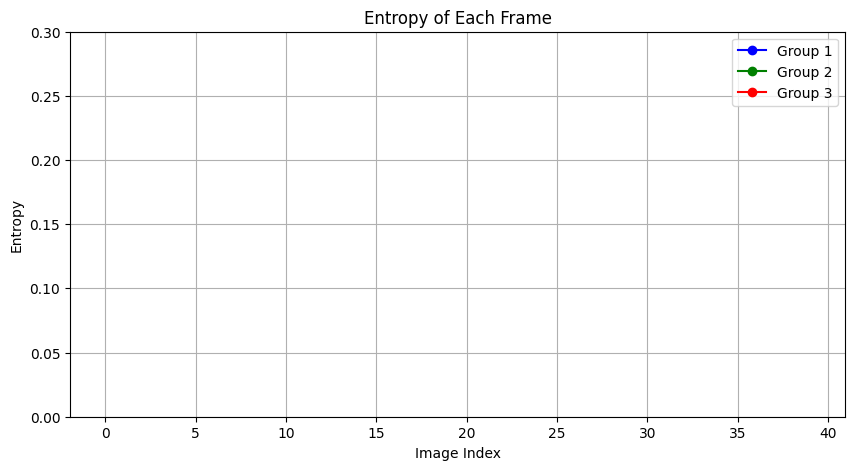

In [21]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

image_entropy_list = []
for decoded_output in dec_vid_list:
    prob = F.softmax(decoded_output[:,:,:,:], dim=-1)
    pixel_entropy = -torch.sum(prob * torch.log(prob + 1e-10), dim=-1)
    image_entropy = pixel_entropy.mean(dim=(1,2))
    image_entropy_list.append(image_entropy)

colors = ['b', 'g', 'r','y', 'c', 'k']
labels = ['Group 1', 'Group 2', 'Group 3', 'Group 4', 'Group 5','Group 6']

plt.figure(figsize=(10, 5))
for i in range(len(image_entropy_list)):
    smoothed_data = gaussian_filter1d(image_entropy_list[i].cpu().numpy(), sigma=1)  # 高斯滤波
    plt.plot(smoothed_data, marker='o', linestyle='-', color=colors[i], label=labels[i])

plt.ylim(0, 0.3)
plt.xlabel("Image Index")
plt.ylabel("Entropy")
plt.title("Entropy of Each Frame")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
image2_entropy_list = []

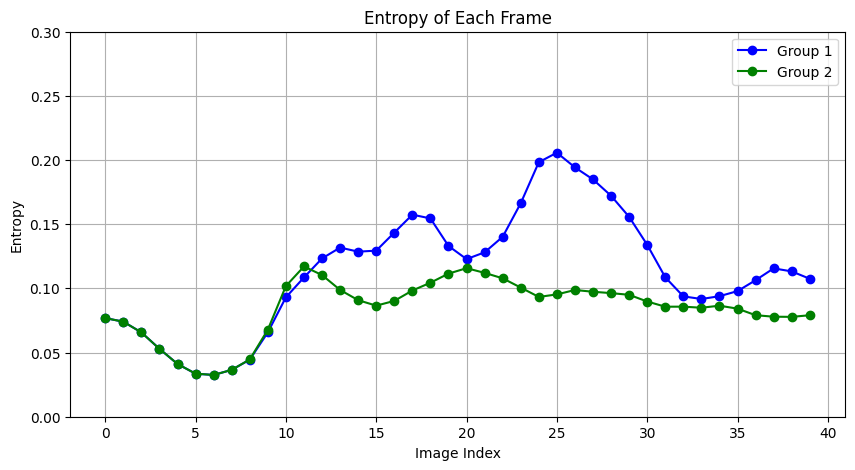

In [29]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

decoded_output = dec_vid_list[0]
prob = F.softmax(decoded_output, dim=-1)
pixel_entropy = -torch.sum(prob * torch.log(prob + 1e-10), dim=-1)
image_entropy = pixel_entropy.mean(dim=(1,2))
image2_entropy_list.append(image_entropy)

colors = ['b', 'g', 'r']
labels = ['Group 1', 'Group 2', 'Group 3']
comb_ent = image2_entropy_list
plt.figure(figsize=(10, 5))
for i in range(len(comb_ent)):
    smoothed_data = gaussian_filter1d(comb_ent[i].cpu().numpy(), sigma=1)  # 高斯滤波
    plt.plot(smoothed_data, marker='o', linestyle='-', color=colors[i], label=labels[i])

plt.ylim(0, 0.3)
plt.xlabel("Image Index")
plt.ylabel("Entropy")
plt.title("Entropy of Each Frame")
plt.legend()
plt.grid(True)
plt.show()

### Variance Calculation

torch.Size([40, 64, 64, 9])


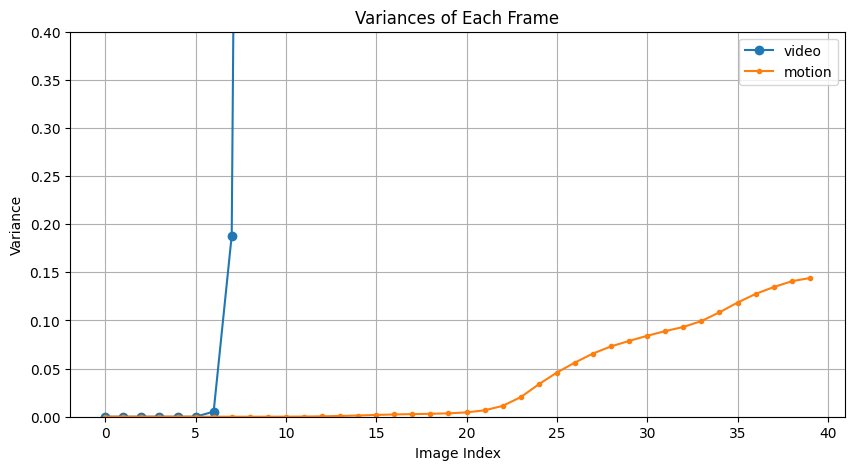

In [9]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

videos = torch.stack(dec_vid_list, axis=0)
motions = torch.stack(rec_mot_list, axis = 0)
variance_vid = torch.var(videos, axis=0)
variance_mot = torch.var(motions, axis=0)

print(variance_vid.shape)
variance_vid = variance_vid.mean(dim=(1,2,3))
variance_mot = variance_mot.mean(dim=(1))

# 计算累计方差
variance_vid = torch.cumsum(variance_vid, dim=0)
variance_mot = torch.cumsum(variance_mot, dim=0)

plt.figure(figsize=(10, 5))

smoothed_data_vid = gaussian_filter1d(variance_vid.cpu().numpy(), sigma=1)  # 高斯滤波
smoothed_data_mot = gaussian_filter1d(variance_mot.cpu().numpy(), sigma=1)  # 高斯滤波

plt.plot(smoothed_data_vid, marker='o', linestyle='-', label = 'video')
plt.plot(smoothed_data_mot, marker='.', linestyle='-', label = 'motion')

plt.ylim(0, 0.4)
plt.xlabel("Image Index")
plt.ylabel("Variance")
plt.title("Variances of Each Frame")
plt.legend()
plt.grid(True)
plt.show()

## 5. Visualization

### Load the dataset

In [10]:
data_origin_path = 'dataset/2024-10-31_xacti_5fps_origin'
# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(data_origin_path, args.sequence_length,rgb=True, train=True, resolution=args.resolution)

# dataloader for the trainning
o_dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

# dataloader for the evaluation
o_dataset = Dataset(data_origin_path, args.sequence_length, rgb=True, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

metadata exists in: dataset/2024-10-31_xacti_5fps_origin/train/metadata_40.pkl
metadata exists in: dataset/2024-10-31_xacti_5fps_origin/test/metadata_40.pkl


In [17]:
o_valid_dataset = Dataset(data_origin_path, args.sequence_length, rgb=True, train=True, resolution=256)

metadata exists in: dataset/2024-10-31_xacti_5fps_origin/train/metadata_40.pkl


731 dataset/2024-10-31_xacti_5fps_origin/train/data_2024-10-24-16_54_21_3m_in_233_sec/18.mp4
li:0.000 ang:0.000
li:0.000 ang:0.100
li:0.007 ang:0.200
li:0.007 ang:0.100
li:0.035 ang:0.100
li:0.189 ang:0.000
li:0.280 ang:0.000
li:0.217 ang:-0.300
li:0.238 ang:-0.300
li:0.287 ang:-0.200
li:0.266 ang:0.000
li:0.294 ang:0.100
li:0.322 ang:0.100
li:0.231 ang:0.000
li:0.301 ang:0.100
li:0.210 ang:0.100
li:0.238 ang:0.300
li:0.266 ang:0.300
li:0.259 ang:0.200
li:0.245 ang:0.300
li:0.315 ang:0.000
li:0.231 ang:-0.100
li:0.238 ang:-0.100
li:0.294 ang:0.000
li:0.259 ang:-0.100
li:0.266 ang:0.000
li:0.350 ang:-0.100
li:0.224 ang:0.000
li:0.217 ang:0.000
li:0.259 ang:0.000
li:0.231 ang:0.000
li:0.252 ang:0.100


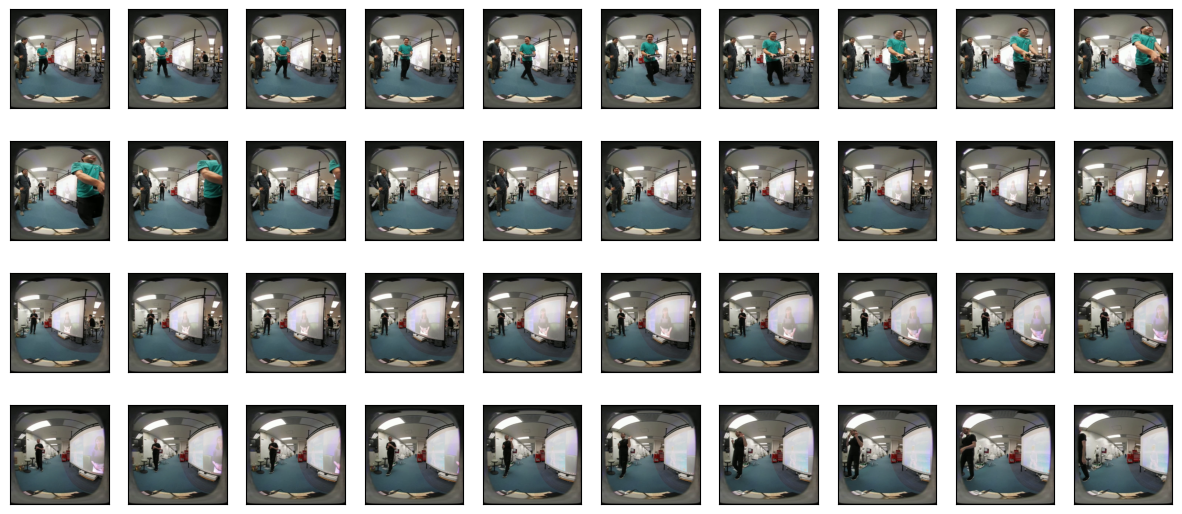

<Figure size 2000x500 with 0 Axes>

In [35]:
# memo: data20240807 1720, 210, 300, 520, 500, 3500
batch, vid_idx, path = o_valid_dataset[idx]
batch, mot = dict.values(batch)
mot = mot.permute(1,0).reshape(1,args.sequence_length,2)
print(vid_idx, path)
visual_vid_mmot(batch, mot, rgb=True,mot_viz=False, grid=False)

### Save the video

In [36]:
import cv2
import numpy as np

# 假设 blended_video 是混合后的帧，形状为 (8, 64, 64, 3)

def save_video(frames, motion, output_path, fps=10):
    # 获取帧的宽度和高度（假设所有帧大小一致）
    height, width, _ = frames[0].shape
    
    # 定义视频编码器, 选择一个合适的编码器，例如 MJPG 或 MP4
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')

    # 创建 VideoWriter 对象
    out = cv2.VideoWriter(output_path, fourcc, fps, (256, 256))
    start_x, start_y = width // 2, height - 5  # 从视频中心开始

    # 将每一帧写入视频
    for i in range(args.sequence_length - frame_t):
        frame = frames[i]
        speed = motion[i, 0]  # 前后的移动速度
        angle = motion[i, 1]  # 转角（弧度）
        # 计算箭头的结束位置
        if (abs(speed) < 0.1) and (abs(angle)<0.1):
            end_x = int(start_x)
            end_y = int(start_y)  
        # elif abs(angle) < 0.1:
        #     end_x = int(start_x)
        #     end_y = int(start_y - 5 * np.cos(angle))  
        else:
            # print(np.sin(angle))
            end_x = int(start_x - 30 * np.sin(angle))
            end_y = int(start_y - 25 * np.cos(angle))  
        # end_x = int(start_x + speed * 1 * np.sin(angle))  
        # end_y = int(start_y + speed * 1 * np.cos(angle))  
        # print(3 * np.sin(angle))
        # print(end_y)

        # 绘制箭头
        arrow_color = (0, 1, 0)  # 绿色箭头
        cv2.arrowedLine(frame, (start_x, start_y), (end_x, end_y), arrow_color, thickness=2, tipLength=0.5)

        # 更新起始位置为当前结束位置
        # start_x, start_y = end_x, end_y

        if frame.dtype == np.float64:
            frame = (frame * 255).astype(np.uint8)
        # 如果帧是 RGB 格式，需要转换为 BGR 格式
        frame_bgr = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)
        frame_bgr = cv2.resize(frame_bgr,(256,256))
        # 写入视频文件
        out.write(frame_bgr)
    
    # 释放 VideoWriter 对象
    out.release()
    print(f"视频已保存为 {output_path}")

########## choose one video generated by model ####################
index = 0
vid = rec_vid_list[index]
mot = rec_mot_list[index][frame_t:].cpu().numpy()
bg_frame = np.float64(batch[frame_t-1].numpy())

########## Resize the generated video to (256,256) ####################
later_frames = vid[frame_t:].cpu().numpy()
resized_frames = []
print(later_frames.shape)
for frame in later_frames:  # 逐帧处理
    resized_frame = np.float64(cv2.resize(frame, (256, 256)))  # 调整为 256x256
    resized_frames.append(resized_frame)

# 转换为 NumPy 数组形式，形状为 (8, 256, 256, channels)
resized_frames = np.array(resized_frames)

alpha = 0
blended_frames = []

for i in range(args.sequence_length - frame_t):
    # 将背景帧与当前帧进行混合
    blended_frame = cv2.addWeighted(bg_frame, alpha, resized_frames[i], 1- alpha, 0)
    blended_frames.append(blended_frame)

blended_video = np.array(blended_frames)




save_video(blended_video, mot, 'output_video.mp4', fps=5)
!echo "y" | ffmpeg -i output_video.mp4 -c:v libx264 -crf 23 -preset fast video1_t.mp4
!rm output_video.mp4

(30, 64, 64, 3)
视频已保存为 output_video.mp4
ffmpeg version 3.4.11-0ubuntu0.1 Copyright (c) 2000-2022 the FFmpeg developers
  built with gcc 7 (Ubuntu 7.5.0-3ubuntu1~18.04)
  configuration: --prefix=/usr --extra-version=0ubuntu0.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --enable-gpl --disable-stripping --enable-avresample --enable-avisynth --enable-gnutls --enable-ladspa --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librubberband --enable-librsvg --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvorbis --enable-libvpx --enable-libwavpack --enable-libwebp --enable-libx265 --ena

In [38]:
from IPython.display import Video,clear_output
clear_output(wait=True)
Video("video1_t.mp4")
